# Realistic-profile SAXS and PCI left/right calculation

This notebook uses `inputs/profiles/RealisticProfile_10nm.tif` as the **intensity immediately before the wire**. The native 4096×4096, 10 nm profile is bilinearly interpolated onto the 4096×4096, 8 nm simulation grid before its field amplitude is formed as `sqrt(intensity)`.

The measured TIFF determines the incident target-plane intensity. Because it has no phase map, the field is assigned the divergent Gaussian wavefront curvature corresponding to a 7.5 Âµm target-plane intensity FWHM. `PCI.XFEL` remains the propagation container on the interpolated 8 nm grid; no Gaussian amplitude envelope replaces the measured intensity.

For each wire offset the notebook calculates:

- PCI target-exit intensity integrated on the left and right sides of the optical axis;
- SAXS detector intensity after 1.31 m propagation, followed by the Mark1300 two-center-row extraction outside $|q_x| < 0.10$ nm$^{-1}$;
- simulated SAXS profile agreement with experimental runs 528, 534, and 546.

Experimental and simulated SAXS profiles are independently peak-normalized for shape comparison. No run-specific multiplicative factors are applied. Run the notebook from either the repository root or `SAXS_asymmetry/`. The 4096² propagations are memory-intensive and intentionally run sequentially.

In [1]:
from pathlib import Path
import gc
import pickle
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from PIL import Image
from scipy import interpolate
from scipy.ndimage import affine_transform, shift as nd_shift
from scipy.optimize import curve_fit

ROOT = Path.cwd()
SAXS_DIR = ROOT / "SAXS_asymmetry" if (ROOT / "SAXS_asymmetry" / "PCI.py").exists() else ROOT
INPUT_DIR = SAXS_DIR / "inputs"
OUTPUT_DIR = SAXS_DIR / "outputs" / "realistic_profile"
FIGURE_DIR = OUTPUT_DIR / "figures"
TIFF_DIR = OUTPUT_DIR / "detector_tiffs"
TABLE_DIR = OUTPUT_DIR / "tables"
for directory in (FIGURE_DIR, TIFF_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

if str(SAXS_DIR) not in sys.path:
    sys.path.insert(0, str(SAXS_DIR))
import PCI

PROFILE_PATH = INPUT_DIR / "profiles" / "RealisticProfile_10nm.tif"
PROFILE_PIXEL_SIZE = 10 * PCI.nm
PIXEL_SIZE = 8 * PCI.nm
N_GRID = 4096
PHOTON_ENERGY = 8.2 * PCI.keV
Z_TARGET = 0.25 * PCI.m
Z_SAXS_DETECTOR = 1.31 * PCI.m
WIRE_RADIUS = 5 * PCI.um
WIRE_VOXEL_SIZE = 20 * PCI.nm
WIRE_VOXEL_NUMBER = 2000
Q_MIN = 0.10
Q_COMPARE_MAX = 0.30
Q_MAX = np.pi / PIXEL_SIZE
OFFSET_STEP_UM = 0.5
WIRE_OFFSETS_UM = np.arange(-10.0, 10.0 + OFFSET_STEP_UM / 2, OFFSET_STEP_UM)
EXPERIMENTAL_RUNS = (528, 534, 546)
GAUSSIAN_REFERENCE_FWHM_UM = 7.5
PROFILE_COMPARISON_OFFSET_UM = 0.0

print(f"Profile: {PROFILE_PATH}")
print(f"Offsets: {WIRE_OFFSETS_UM}")

PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.
Profile: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\inputs\profiles\RealisticProfile_10nm.tif
Offsets: [-10.   -9.5  -9.   -8.5  -8.   -7.5  -7.   -6.5  -6.   -5.5  -5.   -4.5
  -4.   -3.5  -3.   -2.5  -2.   -1.5  -1.   -0.5   0.    0.5   1.    1.5
   2.    2.5   3.    3.5   4.    4.5   5.    5.5   6.    6.5   7.    7.5
   8.    8.5   9.    9.5  10. ]


## 1. Load the realistic target-plane field

The TIFF intensity is bilinearly interpolated from 10 nm to 8 nm while keeping a 4096×4096 calculation grid. This changes the represented field of view from 40.96 µm to 32.768 µm, so the resampling is a centered interpolation and crop. The interpolated intensity is normalized by its total integral and converted to amplitude with a square root. Its measured amplitude is retained, while a divergent 7.5 µm-FWHM Gaussian wavefront supplies the curved target-plane phase.

In [2]:
# Load and preprocess the realistic intensity profile from a TIFF image.
# The TIFF image is expected to contain a square 2-D intensity profile.
# The code will resample this profile to match the PCI grid and normalize the intensity.
# The resulting `incident_intensity` will be used to initialize the PCI field.
# The code uses `scipy.ndimage.affine_transform` for resampling and assumes that the PCI grid is square.
# The code assumes that the TIFF image is in the same units as `PROFILE_PIXEL_SIZE` and that `PIXEL_SIZE` is defined for the PCI grid.


with Image.open(PROFILE_PATH) as profile_image:
    profile_native = np.asarray(profile_image.convert("F"), dtype=np.float32)

profile_native = np.nan_to_num(profile_native, nan=0.0, posinf=0.0, neginf=0.0)
profile_native = np.clip(profile_native, 0.0, None)

# scipy.ndimage.affine_transform maps output indices to input indices.
# Align the zero-coordinate pixels at each array center and sample the native image every 8/10 input pixel using bilinear interpolation.
source_center = np.asarray(profile_native.shape, dtype=float) / 2
target_center = np.asarray((N_GRID, N_GRID), dtype=float) / 2
index_scale = float(PIXEL_SIZE / PROFILE_PIXEL_SIZE)
index_matrix = np.eye(2) * index_scale                          # scale factor for resampling the profile to the PCI grid
index_offset = source_center - index_matrix @ target_center
profile_raw = affine_transform(                                  # profile_raw is the resampled profile on the PCI grid,interpolated from the native image using bilinear interpolation
    profile_native, matrix=index_matrix, offset=index_offset,
    output_shape=(N_GRID, N_GRID), order=1, mode="constant", cval=0.0,
    prefilter=False, output=np.float32,
)
native_integral = np.sum(profile_native, dtype=np.float64) * PROFILE_PIXEL_SIZE**2
resampled_integral = np.sum(profile_raw, dtype=np.float64) * PIXEL_SIZE**2
retained_intensity_fraction = float(resampled_integral / native_integral)

axis_nm = (np.arange(N_GRID) - N_GRID // 2) * PIXEL_SIZE
axis_um = axis_nm / PCI.um
# Normalize total incident intensity to one. This changes only the common
# arbitrary scale, not profile shape, PCI fractions, or SAXS asymmetry.
incident_intensity = profile_raw / np.sum(profile_raw, dtype=np.float64) # incident_intensity is the normalized intensity profile on the PCI grid
incident_intensity = incident_intensity.astype(np.float32, copy=False)
xfel = PCI.XFEL(
    pixel_number=N_GRID, pixel_size=PIXEL_SIZE,
    photon_energy=PHOTON_ENERGY, photon_energy_bandwidth=0 * PCI.eV,
    photon_energy_bandwidth_sample_width=0 * PCI.eV,
)
# Keep the measured TIFF intensity and add the divergent Gaussian
# wavefront curvature for a 7.5 um target-plane intensity FWHM.
wavelength_nm = xfel.get_lambda(photon_energy=PHOTON_ENERGY)
target_beam_radius = GAUSSIAN_REFERENCE_FWHM_UM * PCI.um / np.sqrt(2 * np.log(2))
diffraction_term = wavelength_nm * Z_TARGET / np.pi
phase_source_waist = np.sqrt((
    target_beam_radius**2
    - np.sqrt(target_beam_radius**4 - 4 * diffraction_term**2)
) / 2)
phase_rayleigh_range = np.pi * phase_source_waist**2 / wavelength_nm
phase_wavefront_radius = (Z_TARGET**2 + phase_rayleigh_range**2) / Z_TARGET
phase_1d = np.exp(
    -0.5j * xfel.get_k(photon_energy=PHOTON_ENERGY)
    * axis_nm**2 / phase_wavefront_radius
).astype(np.complex64)
field_at_target = np.sqrt(incident_intensity).astype(np.complex64)
field_at_target *= phase_1d[:, None]
field_at_target *= phase_1d[None, :]
gc.collect()

print(f"Native TIFF grid: {profile_native.shape[0]}² at {PROFILE_PIXEL_SIZE:g} nm")
print(f"Interpolated grid: {N_GRID}² at {PIXEL_SIZE:g} nm; field of view {N_GRID * PIXEL_SIZE / PCI.um:g} um")
print(f"Native intensity range: {profile_native.min():.6g} to {profile_native.max():.6g}")
print(f"Interpolated intensity range: {profile_raw.min():.6g} to {profile_raw.max():.6g}")
print(f"Physical integrated intensity retained after centered crop: {retained_intensity_fraction:.8f}")
print(
    f"Incident phase: divergent {GAUSSIAN_REFERENCE_FWHM_UM:g} um-FWHM curvature; "
    f"source waist={phase_source_waist / PCI.um:.6f} um, "
    f"wavefront radius={phase_wavefront_radius / PCI.m:.6f} m"
)
print(f"Normalized incident intensity sum: {incident_intensity.sum(dtype=np.float64):.8f}")

Native TIFF grid: 4096² at 10 nm
Interpolated grid: 4096² at 8 nm; field of view 32.768 um
Native intensity range: 0 to 254.681
Interpolated intensity range: 1.12568e-08 to 254.662
Physical integrated intensity retained after centered crop: 0.99999811
Incident phase: divergent 7.5 um-FWHM curvature; source waist=1.988233 um, wavefront radius=0.276985 m
Normalized incident intensity sum: 1.00000000


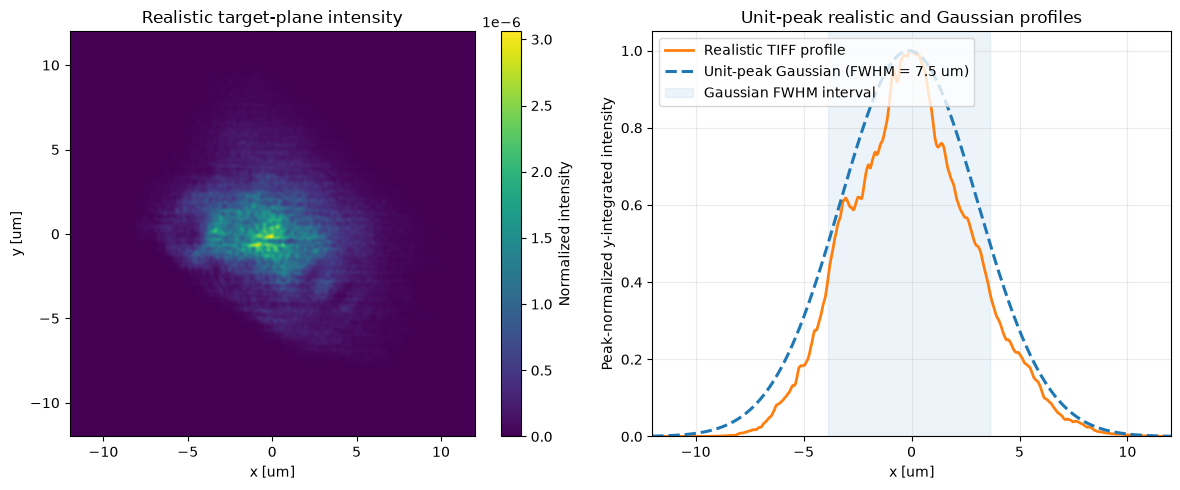

Unit-peak fixed-FWHM Gaussian: peak=1.000000, center=-0.118997 um, FWHM=7.500000 um, RMSE=0.081517, R^2=0.935874
Saved fit table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\tables\realistic_profile_fixed_fwhm_gaussian_fit.dat
Saved: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\figures\00_realistic_incident_profile.png


In [9]:
# Plot the realistic target-plane intensity and fit a unit-peak Gaussian with fixed FWHM to the x-integrated profile.
extent_um = [axis_um[0], axis_um[-1], axis_um[0], axis_um[-1]] # [xmin, xmax, ymin, ymax] in micrometers for imshow extent
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
image = axes[0].imshow(
    incident_intensity, origin="lower", extent=extent_um, cmap="viridis",
    vmin=0, vmax=incident_intensity.max(),
)
axes[0].set(xlabel="x [um]", ylabel="y [um]", title="Realistic target-plane intensity")
axes[0].set_xlim(-12, 12); axes[0].set_ylim(-12, 12)
fig.colorbar(image, ax=axes[0], label="Normalized intensity")
realistic_profile_x = incident_intensity.sum(axis=0, dtype=np.float64)
realistic_profile_x /= realistic_profile_x.max() # normalize the x-integrated profile to have a unit peak

# Both profiles have unit peak. Fit only the Gaussian center while fixing the target-plane intensity FWHM to 7.5 um and the background to zero.
def unit_peak_fixed_fwhm_gaussian(x_um, center_um):
    return np.exp(
        -4 * np.log(2) * ((x_um - center_um) / GAUSSIAN_REFERENCE_FWHM_UM)**2
    )
# Fit the x-integrated realistic profile with the unit-peak Gaussian model.
fit_mask = (axis_um >= -12) & (axis_um <= 12)
fit_parameters, fit_covariance = curve_fit(
    unit_peak_fixed_fwhm_gaussian, axis_um[fit_mask], realistic_profile_x[fit_mask],
    p0=(axis_um[np.argmax(realistic_profile_x)],),
    bounds=((-12.0,), (12.0,)),
)
fit_center_um = float(fit_parameters[0])
fitted_gaussian_x = unit_peak_fixed_fwhm_gaussian(axis_um, fit_center_um)
fitted_gaussian_x /= fitted_gaussian_x.max()  # exact unit peak on the sampled grid
fit_residual = realistic_profile_x[fit_mask] - fitted_gaussian_x[fit_mask]
fit_rmse = float(np.sqrt(np.mean(fit_residual**2)))
fit_r_squared = float(1 - np.sum(fit_residual**2) / np.sum(
    (realistic_profile_x[fit_mask] - realistic_profile_x[fit_mask].mean())**2
))

axes[1].plot(axis_um, realistic_profile_x, color="tab:orange", lw=2, label="Realistic TIFF profile")
axes[1].plot(
    axis_um, fitted_gaussian_x, "--", color="tab:blue", lw=2.2,
    label=f"Unit-peak Gaussian (FWHM = {GAUSSIAN_REFERENCE_FWHM_UM:g} um)",
)
axes[1].axvspan(
    fit_center_um - GAUSSIAN_REFERENCE_FWHM_UM / 2,
    fit_center_um + GAUSSIAN_REFERENCE_FWHM_UM / 2,
    color="tab:blue", alpha=0.08, label="Gaussian FWHM interval",
)
# axes[1].text(
#     0.03, 0.97,
#     f"center = {fit_center_um:+.3f} um\nRMSE = {fit_rmse:.4f}\nR^2 = {fit_r_squared:.4f}",
#     transform=axes[1].transAxes, va="top",
#     bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
# )
axes[1].set(xlabel="x [um]", ylabel="Peak-normalized y-integrated intensity", xlim=(-12, 12), ylim=(0, 1.05), title="Unit-peak realistic and Gaussian profiles")
axes[1].legend(loc="upper left")

for axis in axes[1:]: axis.grid(alpha=0.25)
fig.tight_layout()
profile_fit_table_path = TABLE_DIR / "realistic_profile_fixed_fwhm_gaussian_fit.dat"
np.savetxt(
    profile_fit_table_path,
    np.column_stack((axis_um, realistic_profile_x, fitted_gaussian_x)),
    header=(
        "x_um realistic_y_integrated_unit_peak gaussian_unit_peak; "
        f"fixed_FWHM_um={GAUSSIAN_REFERENCE_FWHM_UM:g} "
        f"peak=1 background=0 center_um={fit_center_um:.10g} "
        f"RMSE={fit_rmse:.10g} R_squared={fit_r_squared:.10g}"
    ),
)
profile_figure_path = FIGURE_DIR / "00_realistic_incident_profile.png"
fig.savefig(profile_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print(
    f"Unit-peak fixed-FWHM Gaussian: peak={fitted_gaussian_x.max():.6f}, "
    f"center={fit_center_um:+.6f} um, FWHM={GAUSSIAN_REFERENCE_FWHM_UM:.6f} um, "
    f"RMSE={fit_rmse:.6f}, R^2={fit_r_squared:.6f}"
  
)
print(f"Saved fit table: {profile_fit_table_path}")
print(f"Saved: {profile_figure_path}")

## 2. Wire model and experimental SAXS profiles

The wire projection and target interpolation are identical to `clean_saxs_design.ipynb`. Experimental runs are reconstructed on signed $q$ without resampling them onto a common grid.

In [4]:
class projected_wire(PCI.wire):
    """Memory-efficient 2-D equivalent of PCI.wire's voxel projection."""
    def _get_projection(self, volume=None):
        transverse_px = np.arange(self.voxel_number) - self.voxel_number // 2
        radius_px = self.radius1_nm / self.voxel_size
        inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
        profile = np.where(
            np.abs(transverse_px) <= radius_px,
            (2 * np.floor(np.sqrt(inside)) + 1) * self.voxel_size,
            0.0,
        )[None, :]
        projection = np.broadcast_to(profile, (self.voxel_number, self.voxel_number)).copy()
        self._density1 = nd_shift(
            projection, np.asarray(self.position_xy) / self.voxel_size,
            order=1, mode="constant", cval=0, prefilter=False,
        )
        return self._density1

def load_experimental_profile(run):
    path = INPUT_DIR / "experimental" / "SAXSData" / f"profiles_cleaned_p3129_r{run:04d}.pickle"
    with path.open("rb") as stream:
        q_positive, left_profile, right_profile = pickle.load(stream)  # Load the positive q values and corresponding left and right profiles from the pickle file
    q_positive = np.asarray(q_positive, dtype=float)
    left_profile = np.nan_to_num(np.asarray(left_profile, dtype=float), nan=0.0)
    right_profile = np.nan_to_num(np.asarray(right_profile, dtype=float), nan=0.0)
    if not (q_positive.shape == left_profile.shape == right_profile.shape):
        raise ValueError(f"run {run} q/left/right arrays do not match")
    keep = np.isfinite(q_positive) & (q_positive >= 0)  # Keep only non-negative and finite q values
    q_positive, left_profile, right_profile = q_positive[keep], left_profile[keep], right_profile[keep]
    order = np.argsort(q_positive)   # Sort q values in ascending order
    q_positive, left_profile, right_profile = q_positive[order], left_profile[order], right_profile[order]
    q_signed = np.concatenate((-q_positive[:0:-1], q_positive))
    intensity_signed = np.concatenate((left_profile[:0:-1], right_profile))
    outer = q_positive >= Q_MIN   # Consider only q values above the minimum threshold for summing left and right profiles
    left = float(np.sum(left_profile[outer]))
    right = float(np.sum(right_profile[outer]))
    scale_mask = (np.abs(q_signed) >= Q_MIN) & (np.abs(q_signed) <= Q_COMPARE_MAX)  # Consider only q values within the comparison range for scaling
    scale = float(np.max(intensity_signed[scale_mask]))
    return {
        "run": run, "path": path, "q": q_signed,
        "intensity": intensity_signed, "normalized": intensity_signed / scale,
        "left": left, "right": right, "left_fraction": left / (left + right),
    }

experimental_profiles = {run: load_experimental_profile(run) for run in EXPERIMENTAL_RUNS}
for run, profile in experimental_profiles.items():
    print(
        f"Run {run}: L={profile['left']:.6g}, R={profile['right']:.6g}, "
        f"L/(L+R)={profile['left_fraction']:.5f}, {profile['path'].name}"
    )
experimental_side_table_path = TABLE_DIR / "experimental_runs_528_534_546_saxs_left_right.dat"
np.savetxt(
    experimental_side_table_path,
    np.array([[run, p['left'], p['right'], p['left_fraction']] for run, p in experimental_profiles.items()]),
    header="run left_raw right_raw left_over_left_plus_right; abs(q)>=0.10 nm^-1",
)
print(f"Saved experimental side table: {experimental_side_table_path}")

# Existing divergent Gaussian Mark1300 reference from clean_saxs_design.
gaussian_tag = f"{GAUSSIAN_REFERENCE_FWHM_UM:g}".replace(".", "p")
gaussian_table_path = SAXS_DIR / "outputs" / "saxs" / "tables" / f"DivSAXS_asymmetry_Mark1300_{gaussian_tag}um.dat"
gaussian_scan = np.loadtxt(gaussian_table_path)
gaussian_offsets_um = gaussian_scan[:, 0] / 1e3
gaussian_left = gaussian_scan[:, 1]
gaussian_right = gaussian_scan[:, 2]
gaussian_total = gaussian_left + gaussian_right
gaussian_left_fraction = gaussian_left / gaussian_total
gaussian_detector_path = (
    SAXS_DIR / "outputs" / "saxs" / "detector_tiffs" / f"Data_{PIXEL_SIZE:g}nm"
    / f"mark1300_{gaussian_tag}um" / f"SAXS_Offset{PROFILE_COMPARISON_OFFSET_UM:.2f}um.tif"
)
with Image.open(gaussian_detector_path) as gaussian_detector_image:
    gaussian_detector_intensity = np.asarray(gaussian_detector_image, dtype=np.float32).copy()
gaussian_profile_lineout = gaussian_detector_intensity[N_GRID // 2 - 5:N_GRID // 2 + 5, :].mean(axis=0, dtype=np.float64)   # Average over 10 central rows to obtain the lineout profile
del gaussian_detector_intensity

motor_dir = INPUT_DIR / "experimental" / "Erik"
motor_positions_um = np.load(motor_dir / "motor_positions_um.npy").astype(float)
motor_left_fraction = np.load(motor_dir / "left_div_left_right_exp.npy").astype(float)
erik_offsets_um = np.load(motor_dir / "pos_grid.npy").astype(float) / 1e3
erik_left_over_right = np.load(motor_dir / "left_div_right.npy").astype(float)
erik_left_fraction = erik_left_over_right / (1.0 + erik_left_over_right)
if motor_positions_um.shape != motor_left_fraction.shape:
    raise ValueError("motor positions and measured left fractions must have matching shapes")
if erik_offsets_um.shape != erik_left_fraction.shape:
    raise ValueError("Erik positions and simulated left fractions must have matching shapes")

lingen_table_path = SAXS_DIR / "outputs" / "saxs" / "tables" / "DivSAXS_asymmetry_Mark1300_6um_lg.dat"
lingen_scan = np.loadtxt(lingen_table_path)
lingen_offsets_um = lingen_scan[:, 0] / 1e3
lingen_left_fraction = lingen_scan[:, 1] / (lingen_scan[:, 1] + lingen_scan[:, 2])

# Centered 6 um SAXS profile generated by SAXS_Asymmetry_Methods.ipynb.
methods_profile_path = (
    SAXS_DIR / "cache" / "methods"
    / f"Method1CacheV2_N{N_GRID}_Pix{PIXEL_SIZE:g}nm_FWHM6um_Mark522"
    / "offset_p0p00um.pickle"
)
with methods_profile_path.open("rb") as stream:
    methods_profile_record = pickle.load(stream)
methods_profile_q = experimental_profiles[528]["q"]
methods_profile_lineout = np.asarray(methods_profile_record["pointing_lineout"], dtype=float)
if methods_profile_q.shape != methods_profile_lineout.shape:
    raise ValueError("Methods q axis and centered SAXS profile must have matching shapes")
print(f"Loaded Gaussian reference: {gaussian_table_path}")
print(f"Loaded Gaussian detector profile: {gaussian_detector_path}")
print(f"Loaded motor left-ratio data: {len(motor_positions_um)} points")
print(f"Loaded Erik collimated simulation: {len(erik_offsets_um)} points")
print(f"Loaded Lingen Mark1300 table: {lingen_table_path}")
print(f"Loaded Methods centered SAXS profile: {methods_profile_path}")

Run 528: L=248.128, R=257.884, L/(L+R)=0.49036, profiles_cleaned_p3129_r0528.pickle
Run 534: L=113.461, R=325.357, L/(L+R)=0.25856, profiles_cleaned_p3129_r0534.pickle
Run 546: L=114.141, R=113.638, L/(L+R)=0.50110, profiles_cleaned_p3129_r0546.pickle
Saved experimental side table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\tables\experimental_runs_528_534_546_saxs_left_right.dat
Loaded Gaussian reference: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_7p5um.dat
Loaded Gaussian detector profile: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\detector_tiffs\Data_8nm\mark1300_7p5um\SAXS_Offset0.00um.tif
Loaded motor left-ratio data: 20 points
Loaded Erik collimated simulation: 100 points
Loaded Lingen Mark1300 table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\saxs\tables\DivSAXS_asymmetry_Mark1300_6um_lg.dat


## 3. Sequential realistic-profile offset scan

PCI is evaluated immediately after the target, matching the exit-plane definition used by the clean PCI comparison. SAXS is Fresnel-propagated to the detector. Detector TIFFs are reopened before the two-row Mark1300 extraction.

In [5]:
q_axis = np.linspace(-Q_MAX, Q_MAX, N_GRID)
center = N_GRID // 2
left_q_mask = q_axis < -Q_MIN
right_q_mask = q_axis > Q_MIN
left_x_weights = (axis_nm < 0).astype(np.float32) 
right_x_weights = (axis_nm > 0).astype(np.float32)
on_axis = np.isclose(axis_nm, 0.0, rtol=0.0, atol=PIXEL_SIZE / 2) 
left_x_weights[on_axis] = 0.5   # Split the weight equally for the on-axis pixels
right_x_weights[on_axis] = 0.5
incident_total = float(np.sum(incident_intensity, dtype=np.float64))

def simulate_offset(wire_offset_um):
    target = projected_wire(
        "wire", photon_Energy=PHOTON_ENERGY, radius=WIRE_RADIUS, material=PCI.Cu,
        position=[0, wire_offset_um * PCI.um, Z_TARGET],
        voxel_size=WIRE_VOXEL_SIZE, voxel_number=WIRE_VOXEL_NUMBER,
    )
    exit_field = xfel.propagate_through_target(
        target, reset=False, field_in=field_at_target, photon_energy=PHOTON_ENERGY,
    )
    pci_exit_intensity = np.abs(exit_field)**2
    pci_left = float(np.sum(pci_exit_intensity * left_x_weights[None, :], dtype=np.float64))
    pci_right = float(np.sum(pci_exit_intensity * right_x_weights[None, :], dtype=np.float64))
    
    saxs_field = xfel.lorentz_propagate_to_position(
        position=Z_SAXS_DETECTOR, field_in=exit_field,
        photon_energy=PHOTON_ENERGY, reset=False,
    )
    saxs_intensity = np.asarray(np.abs(saxs_field)**2, dtype=np.float32)
    offset_tag = f"{wire_offset_um:+.1f}".replace("+", "p").replace("-", "m").replace(".", "p") # Convert the wire offset to a string suitable for filenames
    detector_path = TIFF_DIR / f"SAXS_realistic_offset_{offset_tag}um.tif"
    Image.fromarray(saxs_intensity).save(detector_path, format="TIFF", compression="tiff_deflate")
    with Image.open(detector_path) as detector_image:
        reopened = np.asarray(detector_image, dtype=np.float32).copy()
    mark_lineout = reopened[center - 5:center + 5, :].mean(axis=0, dtype=np.float64) # Average over 10 central rows to obtain the lineout profile
    saxs_left = float(np.sum(mark_lineout[left_q_mask]))
    saxs_right = float(np.sum(mark_lineout[right_q_mask]))
    
    record = {
        "offset_um": float(wire_offset_um),
        "pci_left": pci_left, "pci_right": pci_right,
        "pci_left_fraction": pci_left / (pci_left + pci_right),
        "pci_total_over_incident": (pci_left + pci_right) / incident_total,
        "saxs_left": saxs_left, "saxs_right": saxs_right,
        "saxs_left_fraction": saxs_left / (saxs_left + saxs_right),
        "saxs_lineout": mark_lineout, "detector_path": detector_path,
    }
    del target, exit_field, pci_exit_intensity, saxs_field, saxs_intensity, reopened
    gc.collect()
    return record

simulation_records = []
for index, offset_um in enumerate(WIRE_OFFSETS_UM, start=1):
    print(f"[{index}/{len(WIRE_OFFSETS_UM)}] wire offset {offset_um:+.1f} um", flush=True)
    simulation_records.append(simulate_offset(float(offset_um)))

print("Offset scan complete.")

[1/41] wire offset -10.0 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[2/41] wire offset -9.5 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[3/41] wire offset -9.0 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[4/41] wire offset -8.5 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[5/41] wire offset -8.0 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[6/41] wire offset -7.5 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[7/41] wire offset -7.0 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[8/41] wire offset -6.5 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[9/41] wire offset -6.0 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[10/41] wire offset -5.5 um
mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000
[11/41] wire offset -5.0 um
mu is 4.0906392887346616e-05 [

## 4. Save PCI and SAXS left/right tables

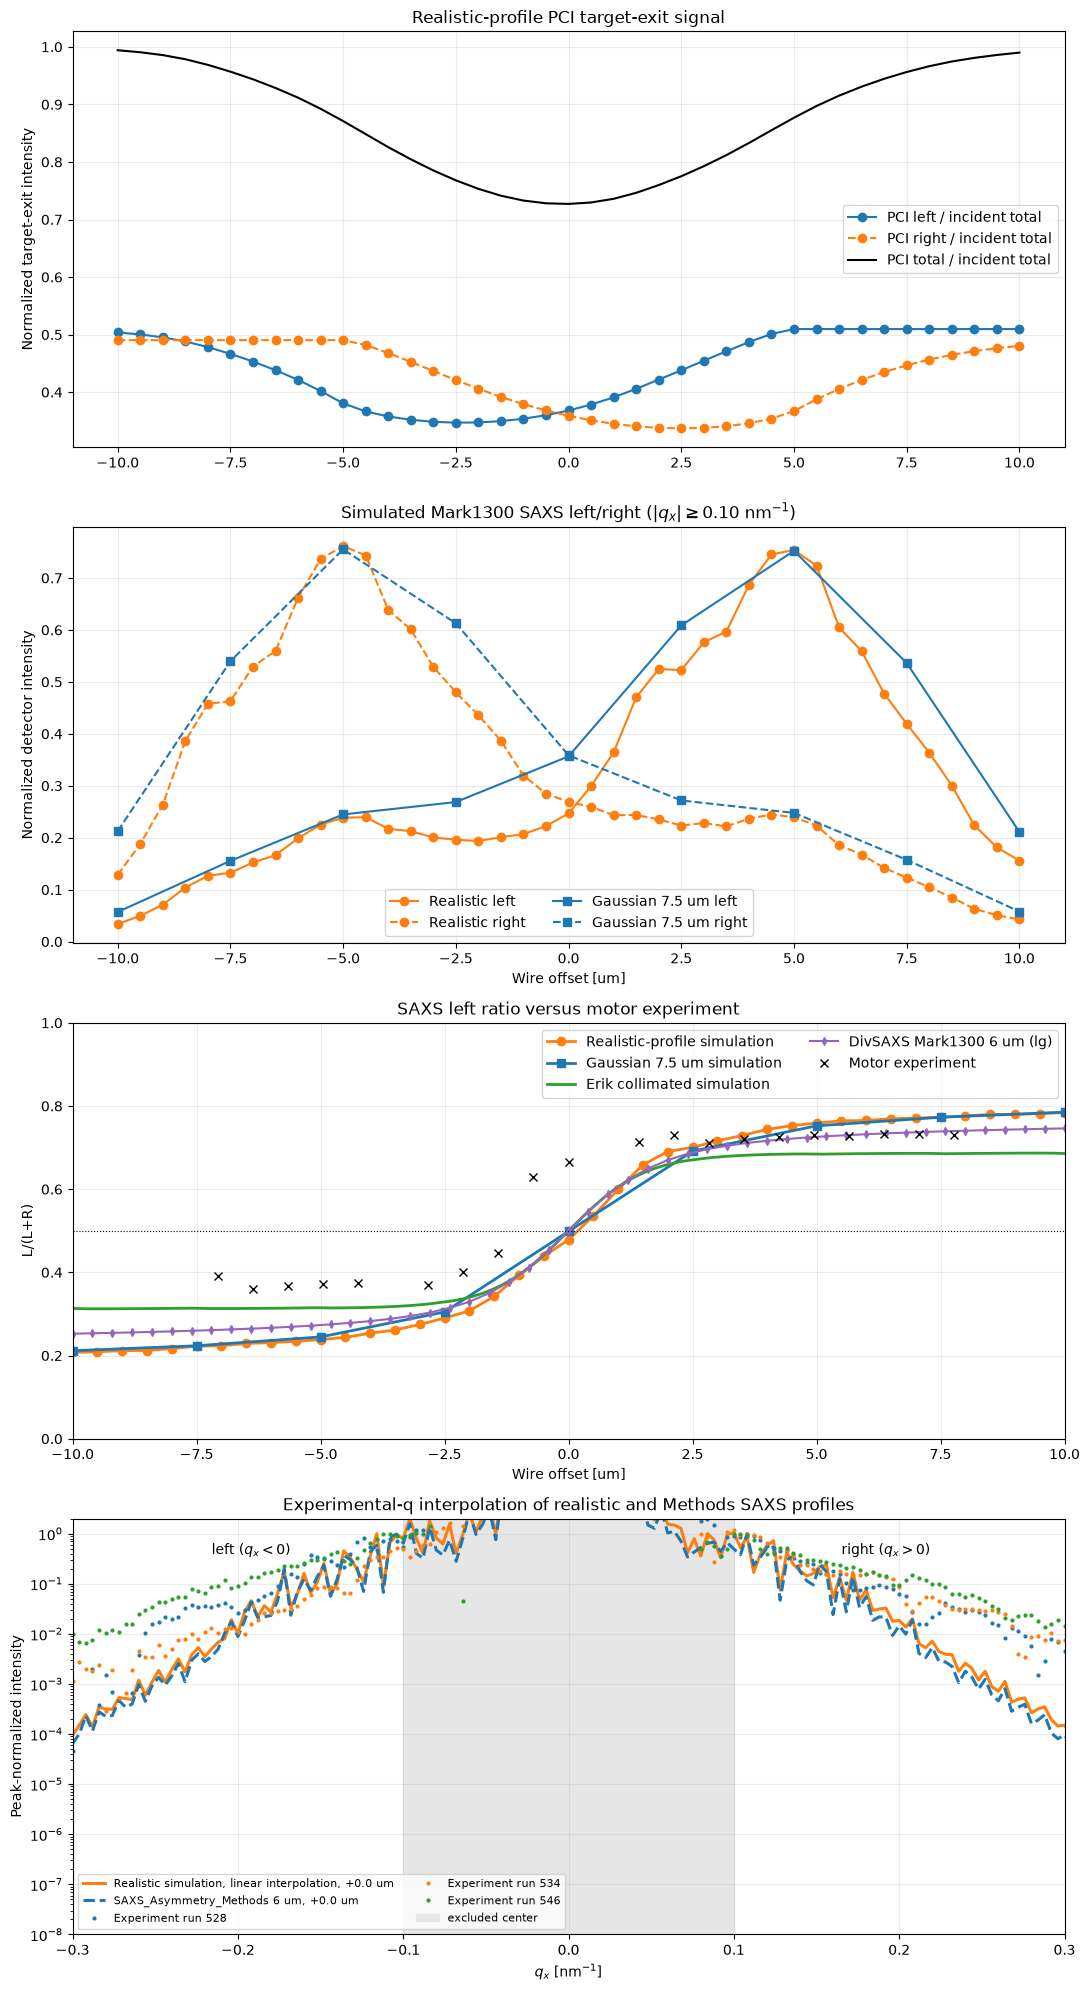

Saved PCI table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\tables\realistic_profile_pci_exit_left_right.dat
Saved SAXS table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\tables\realistic_profile_saxs_left_right.dat
Saved overview: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\figures\01_realistic_pci_saxs_left_right.png


In [11]:
offsets_um = np.array([record["offset_um"] for record in simulation_records])
pci_left = np.array([record["pci_left"] for record in simulation_records])
pci_right = np.array([record["pci_right"] for record in simulation_records])
pci_total = pci_left + pci_right
pci_left_fraction = pci_left / pci_total
saxs_left = np.array([record["saxs_left"] for record in simulation_records])
saxs_right = np.array([record["saxs_right"] for record in simulation_records])
saxs_total = saxs_left + saxs_right
saxs_left_fraction = saxs_left / saxs_total

pci_table_path = TABLE_DIR / "realistic_profile_pci_exit_left_right.dat"
np.savetxt(
    pci_table_path,
    np.column_stack((offsets_um, pci_left, pci_right, pci_total, pci_left_fraction, pci_total / incident_total)),
    header="offset_um left_exit_raw right_exit_raw total_exit_raw left_over_left_plus_right total_exit_over_incident",
)
saxs_table_path = TABLE_DIR / "realistic_profile_saxs_left_right.dat"
np.savetxt(
    saxs_table_path,
    np.column_stack((offsets_um * 1e3, saxs_left, saxs_right, saxs_left_fraction)),
    header="offset_nm left_raw right_raw left_over_left_plus_right; Mark1300 two-row extraction; abs(qx)>=0.10 nm^-1",
)

fig, axes = plt.subplots(4, 1, figsize=(11, 20))
axes[0].plot(offsets_um, pci_left / incident_total, "o-", label="PCI left / incident total")
axes[0].plot(offsets_um, pci_right / incident_total, "o--", label="PCI right / incident total")
axes[0].plot(offsets_um, pci_total / incident_total, "k-", label="PCI total / incident total")
axes[0].set(ylabel="Normalized target-exit intensity", title="Realistic-profile PCI target-exit signal")
axes[0].legend()
saxs_scale = np.max(saxs_total)
gaussian_scale = np.max(gaussian_total)
axes[1].plot(offsets_um, saxs_left / saxs_scale, "o-", color="tab:orange", label="Realistic left")
axes[1].plot(offsets_um, saxs_right / saxs_scale, "o--", color="tab:orange", label="Realistic right")
axes[1].plot(gaussian_offsets_um, gaussian_left / gaussian_scale, "s-", color="tab:blue", label=f"Gaussian {GAUSSIAN_REFERENCE_FWHM_UM:g} um left")
axes[1].plot(gaussian_offsets_um, gaussian_right / gaussian_scale, "s--", color="tab:blue", label=f"Gaussian {GAUSSIAN_REFERENCE_FWHM_UM:g} um right")
axes[1].set(xlabel="Wire offset [um]", ylabel="Normalized detector intensity", title=r"Simulated Mark1300 SAXS left/right ($|q_x|\geq0.10$ nm$^{-1}$)")
axes[1].legend(ncol=2)

# axes[2]: left-ratio comparison on the measured motor coordinate.
axes[2].plot(offsets_um, saxs_left_fraction, "o-", lw=2, color="tab:orange", label="Realistic-profile simulation")
axes[2].plot(gaussian_offsets_um, gaussian_left_fraction, "s-", lw=2, color="tab:blue", label=f"Gaussian {GAUSSIAN_REFERENCE_FWHM_UM:g} um simulation")
axes[2].plot(erik_offsets_um, erik_left_fraction, "-", lw=2, color="tab:green", label="Erik collimated simulation")
axes[2].plot(lingen_offsets_um, lingen_left_fraction, "d-", ms=4, color="tab:purple", label="DivSAXS Mark1300 6 um (lg)")
axes[2].plot(motor_positions_um, motor_left_fraction, "kx", ms=6, label="Motor experiment")
axes[2].axhline(0.5, color="k", lw=0.8, ls=":")
axes[2].set(xlabel="Wire offset [um]", ylabel="L/(L+R)", xlim=(-10, 10), ylim=(0, 1), title="SAXS left ratio versus motor experiment")
axes[2].legend(ncol=2)

# axes[3]: signed-q profiles; q<0 is left and q>0 is right.
profile_record = min(simulation_records, key=lambda record: abs(record["offset_um"] - PROFILE_COMPARISON_OFFSET_UM))
realistic_profile_raw = profile_record["saxs_lineout"].astype(float)
realistic_profile_interpolated = interpolate.interp1d(
    q_axis, realistic_profile_raw, kind="linear", fill_value="extrapolate"
)(methods_profile_q)
profile_q_mask = (np.abs(methods_profile_q) >= Q_MIN) & (np.abs(methods_profile_q) <= Q_COMPARE_MAX)
realistic_profile_interpolated /= np.max(realistic_profile_interpolated[profile_q_mask])
methods_profile_mask = (np.abs(methods_profile_q) >= Q_MIN) & (np.abs(methods_profile_q) <= Q_COMPARE_MAX)
methods_profile_normalized = methods_profile_lineout / np.max(methods_profile_lineout[methods_profile_mask])
axes[3].semilogy(methods_profile_q, np.maximum(realistic_profile_interpolated, 1e-10), "-", lw=2.2, color="tab:orange", label=f"Realistic simulation, linear interpolation, {profile_record['offset_um']:+.1f} um")
axes[3].semilogy(methods_profile_q, np.maximum(methods_profile_normalized, 1e-10), "--", lw=2.2, color="tab:blue", label="SAXS_Asymmetry_Methods 6 um, +0.0 um")
for run, profile in experimental_profiles.items():
    axes[3].semilogy(profile["q"], np.maximum(profile["normalized"], 1e-10), ".", ms=4, label=f"Experiment run {run}")
axes[3].axvspan(-Q_MIN, Q_MIN, color="0.9", label="excluded center")
axes[3].text(0.18, 0.94, "left ($q_x<0$)", transform=axes[3].transAxes, ha="center", va="top")
axes[3].text(0.82, 0.94, "right ($q_x>0$)", transform=axes[3].transAxes, ha="center", va="top")
axes[3].set(xlabel=r"$q_x$ [nm$^{-1}$]", ylabel="Peak-normalized intensity", xlim=(-Q_COMPARE_MAX, Q_COMPARE_MAX), ylim=(1e-8, 2), title="Experimental-q interpolation of realistic and Methods SAXS profiles")
axes[3].legend(fontsize=8, ncol=2)
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
overview_path = FIGURE_DIR / "01_realistic_pci_saxs_left_right.png"
fig.savefig(overview_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved PCI table: {pci_table_path}")
print(f"Saved SAXS table: {saxs_table_path}")
print(f"Saved overview: {overview_path}")

## 5. Compare simulated SAXS profiles with runs 528, 534, and 546

For every run and simulated offset, the code computes an RMS difference in $\log_{10}$ intensity over $0.10 \le |q_x| \le 0.30$ nm$^{-1}$. Both profiles are independently peak-normalized in that interval. This compares shape and asymmetry without an arbitrary multiplicative factor.

Run 528: best offset=+0.50 um, log-RMS=0.72192, experimental L/(L+R)=0.49036, simulation=0.53556
Run 534: best offset=-10.00 um, log-RMS=0.74182, experimental L/(L+R)=0.25856, simulation=0.20762
Run 546: best offset=+0.50 um, log-RMS=1.06309, experimental L/(L+R)=0.50110, simulation=0.53556


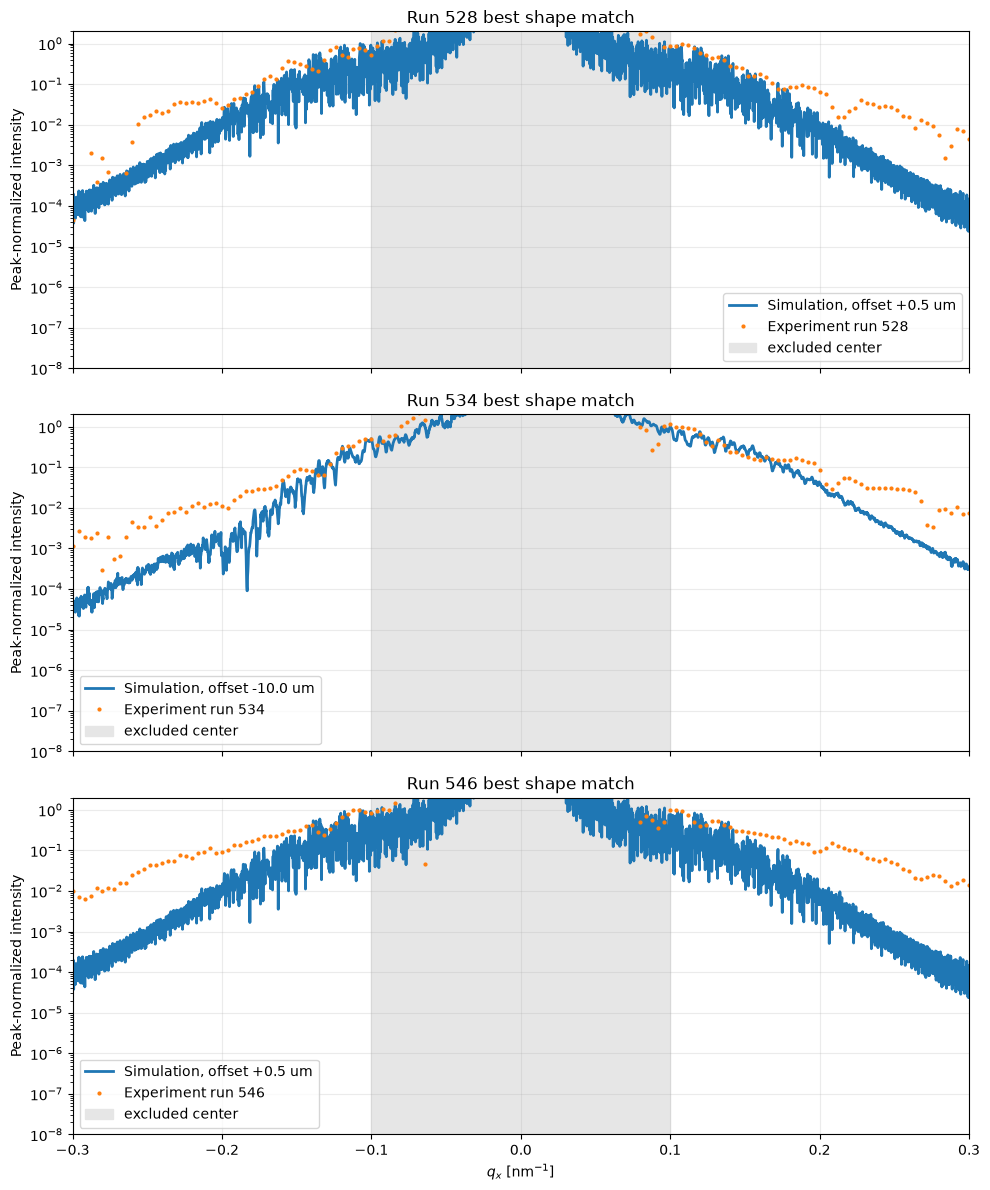

Saved comparison table: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\tables\realistic_profile_experimental_best_matches.dat
Saved comparison figure: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\realistic_profile\figures\02_realistic_saxs_vs_runs_528_534_546.png


In [10]:
def normalized_log_rms(record, experimental):
    q_exp = experimental["q"]
    exp_values = experimental["normalized"]
    model_values = np.interp(q_exp, q_axis, record["saxs_lineout"], left=np.nan, right=np.nan)
    mask = (
        np.isfinite(model_values) & np.isfinite(exp_values)
        & (np.abs(q_exp) >= Q_MIN) & (np.abs(q_exp) <= Q_COMPARE_MAX)
        & (model_values >= 0) & (exp_values >= 0)
    )
    if np.count_nonzero(mask) < 10:
        return np.inf
    model = model_values[mask]
    experiment = exp_values[mask]
    model /= np.max(model)
    experiment /= np.max(experiment)
    floor = 1e-10
    return float(np.sqrt(np.mean((np.log10(np.maximum(model, floor)) - np.log10(np.maximum(experiment, floor)))**2)))

comparison_rows = []
best_records = {}
for run, experimental in experimental_profiles.items():
    scores = np.array([normalized_log_rms(record, experimental) for record in simulation_records])
    best_index = int(np.argmin(scores))
    best = simulation_records[best_index]
    best_records[run] = best
    comparison_rows.append([
        run, best["offset_um"], scores[best_index], experimental["left_fraction"], best["saxs_left_fraction"],
    ])
    print(
        f"Run {run}: best offset={best['offset_um']:+.2f} um, log-RMS={scores[best_index]:.5f}, "
        f"experimental L/(L+R)={experimental['left_fraction']:.5f}, "
        f"simulation={best['saxs_left_fraction']:.5f}"
    )

comparison_table_path = TABLE_DIR / "realistic_profile_experimental_best_matches.dat"
np.savetxt(
    comparison_table_path, np.asarray(comparison_rows),
    header="run best_offset_um normalized_log10_rms experimental_left_fraction simulated_left_fraction",
)

fig, axes = plt.subplots(len(EXPERIMENTAL_RUNS), 1, figsize=(10, 12), sharex=True)
for axis, run in zip(axes, EXPERIMENTAL_RUNS):
    experimental = experimental_profiles[run]
    best = best_records[run]
    model = best["saxs_lineout"].astype(float)
    model_mask = (np.abs(q_axis) >= Q_MIN) & (np.abs(q_axis) <= Q_COMPARE_MAX)
    model /= np.max(model[model_mask])
    axis.semilogy(q_axis, np.maximum(model, 1e-10), "-", lw=2, label=f"Simulation, offset {best['offset_um']:+.1f} um")
    axis.semilogy(experimental["q"], np.maximum(experimental["normalized"], 1e-10), ".", ms=4, label=f"Experiment run {run}")
    axis.axvspan(-Q_MIN, Q_MIN, color="0.9", label="excluded center")
    axis.set(ylabel="Peak-normalized intensity", xlim=(-Q_COMPARE_MAX, Q_COMPARE_MAX), ylim=(1e-8, 2), title=f"Run {run} best shape match")
    axis.grid(alpha=0.25)
    axis.legend()
axes[-1].set_xlabel(r"$q_x$ [nm$^{-1}$]")
fig.tight_layout()
comparison_figure_path = FIGURE_DIR / "02_realistic_saxs_vs_runs_528_534_546.png"
fig.savefig(comparison_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved comparison table: {comparison_table_path}")
print(f"Saved comparison figure: {comparison_figure_path}")

## Interpretation notes

- The TIFF determines the full incident intensity, including asymmetry and fine structure.
- The TIFF determines the full incident intensity, while a divergent 7.5 µm-FWHM Gaussian reference supplies only the wavefront curvature.
- PCI left/right values are target-exit half-plane integrals. Runs 528, 534, and 546 contain SAXS profiles, so the direct experimental comparison is made for SAXS.
- The interpolated 8 nm grid has a Nyquist limit of approximately 0.393 nm$^{-1}$; comparisons stop at 0.30 nm$^{-1}$.
- The lowest-RMS comparison offset is selected only from the configured offset grid. Reduce `OFFSET_STEP_UM` for a finer scan.